# 29. Uncertainty of the model-ranking reversal, and the same baseline applied to a daily VIX stress design

Part A extends notebook 22 on the Bitcoin development period. In notebook 22 the top model on standard AUC changed with the event-definition window (prior high over 2, 4, 8 or 24 hours): 24-hour realized volatility at 2 hours, M0 and M1 at 4 hours, GBM at 8 and 24 hours. To check whether this reversal is chance, I compute:
- 95% intervals of **between-model differences** (GBM − M0, realized volatility − M0, GBM − realized volatility) in standard AUC, pre-onset AUC and pre-onset AUC within the same volatility decile, with shared block-bootstrap weights.
- The crossover share π\*: since standard AUC = (1 − π)·pre-onset AUC + π·in-progress AUC, two models have equal standard AUC at the in-progress share π\* = Δpre / (Δpre − Δin), defined when the two differences have opposite signs. When the actual π exceeds π\*, the model that scores the in-progress stretch better ranks first.
- Paired event-level tests per method pair (McNemar, Holm correction within each window and endpoint) on the notebook 16 stored alerts matched to the events of each window.

Part B applies the same baseline to the US daily VIX stress design of Le & Hoang (2026). I build this design from FRED public data (VIXCLS, NASDAQCOM, 1990-01-02 to 2026-07-20).
- Stress = VIX ≥ 25; I evaluate only days with VIX < 25; positive = VIX ≥ 25 within the next h (1, 3, 5, 10) trading days. Training 1990–2014, validation 2015–2017, test 2018 to 2026-07-20; I drop days whose target window crosses a split boundary. Features: their five market variables (VIX, 1-day VIX change, 5-day VIX mean, NASDAQ daily return, NASDAQ 20-day standard deviation).
- Models: logistic, LASSO logistic, random forest and gradient boosting (sklearn HGB as an XGBoost stand-in). For each h I select one on validation PR-AUC, refit it on 1990–2017 and test it. Baselines (no fitting): the current VIX level, the 5-day VIX mean and NASDAQ 20-day volatility.
- Within-regime AUC: AUC over positive–negative pairs in the same VIX bin only (1-point bins; deciles as secondary). A value near 0.5 means the skill is the VIX level (regime).
- Run-up decomposition: the share π of positive days on which VIX was already rising, and its contribution, under three run-up definitions that I fixed in advance and report in full.
- Alert-budget frontier: detection rates of the one-line rule "VIX ≥ c" and of the selected model at 5, 10, 20 and 40 false-alarm days per year, next to the values Le & Hoang report (their Figure 3).

I pre-specified the reading rules in `29_SPEC.json` before seeing the real-data results. A: at each window, I read the ranking reversal as beyond sampling variation if the 95% interval of the GBM − M0 standard-AUC difference lies above (or below) 0, and report it as "not distinguishable" otherwise. B: for each h, if (i) the 95% interval of the selected model's test ROC-AUC minus the VIX-level ROC-AUC includes 0 or lies below 0 and (ii) the 95% interval of its AUC within 1-point VIX bins includes 0.5, its onset skill is "not shown to exceed the VIX level (volatility regime)"; if the interval in (ii) lies above 0.5, it "carries information beyond the VIX level". I report every h and select none.

This analysis is exploratory and descriptive. I use only the Bitcoin development period and leave the holdouts untouched; the notebook is unrelated to the preregistered rules. I write the results to `ranking_vix_baseline_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

OUT = SPOT_BASE / 'ranking_vix_baseline_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
M22 = SPOT_BASE / 'peak_window_v1'
DNAME, DCL = '4pct', 0.04
H_LIST = [120, 240, 480, 1440]; H_REF = 240
PSCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']
PAIRS = [('M3_GBM_rich', 'M0_VF_logit'), ('B0_RV24h_baseline', 'M0_VF_logit'), ('M3_GBM_rich', 'B0_RV24h_baseline')]
ALERT_METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
RUN_PART_A = True          # False: skip Part A and read its saved results (for a Part-B-only rerun)
N_BOOT = 500; SEED = 20261111; BLOCK_DAYS = 7; N_EVBOOT = 30000
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS

FRED_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id={}'
CBOE_VIX_URL = 'https://cdn.cboe.com/api/global/us_indices/daily_prices/VIX_History.csv'
FRED_IDS = ['VIXCLS', 'NASDAQCOM']
RAWV = DRIVE / 'FRED_daily'; RAWV.mkdir(parents=True, exist_ok=True)
V_START, V_END = pd.Timestamp('1990-01-01'), pd.Timestamp('2026-07-20')
SPLIT_EDGES = {'train': ('1990-01-01', '2014-12-31'), 'validation': ('2015-01-01', '2017-12-31'), 'test': ('2018-01-01', '2026-07-20')}
VIX_TH = 25.0; HORIZONS = [1, 3, 5, 10]; VBOOT = 400; VBLOCK = 20; BUDGETS = [5, 10, 20, 40]
VFEATS = ['vix', 'dvix1', 'vix_ma5', 'nq_ret', 'nq_rv20']
LASSO_C = [0.01, 0.03, 0.1, 0.3, 1.0]
# Reported in Le & Hoang (2026), SSRN 7390122: Table 1-3, Appendix Table 2 (market-only logistic and LASSO), Figure 3. For side-by-side reading only.
LH = {'table1_eligible': {1: 7555, 3: 7553, 5: 7551, 10: 7546}, 'table1_positive': {1: 167, 3: 390, 5: 559, 10: 897},
      'test_n': {1: 1772, 3: 1770, 5: 1768, 10: 1763}, 'test_prevalence_pct': {1: 2.71, 3: 6.21, 5: 9.16, 10: 16.05},
      'selected': {1: 'LASSO, integrated', 3: 'XGBoost, integrated', 5: 'XGBoost, integrated', 10: 'Random forest, market-only'},
      'selected_roc': {1: 0.917, 3: 0.853, 5: 0.801, 10: 0.775}, 'selected_pr': {1: 0.285, 3: 0.316, 5: 0.313, 10: 0.413},
      'market_logit_roc': {1: 0.917, 3: 0.870, 5: 0.837, 10: 0.793}, 'market_logit_pr': {1: 0.265, 3: 0.379, 5: 0.404, 10: 0.458},
      'market_lasso_roc': {1: 0.916, 3: 0.869, 5: 0.837, 10: 0.792}, 'market_lasso_pr': {1: 0.302, 3: 0.382, 5: 0.403, 10: 0.457},
      'episodes_test': 48,
      'frontier_edr_pct': {1: {5: 18.8, 10: 45.8, 20: 75.0, 40: 89.6}, 3: {5: 12.5, 10: 41.7, 20: 75.0, 40: 91.7},
                           5: {5: 12.5, 10: 54.2, 20: 56.2, 40: 87.5}, 10: {5: 54.2, 10: 77.1, 20: 91.7, 40: 93.8}}}
RUNUP_DEFS = {'R1_quarter_way': 'VIX has covered at least a quarter of the distance from its trailing 20-day low to 25',
              'R2_20pct_above_low': 'VIX is at least 20% above its trailing 20-day low',
              'R3_vix_ge_20': 'VIX is at or above 20'}

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M16 / '4_methods_definitions_nulls.csv', M22 / '2_per_minute_by_window.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 16 and 22 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Ranking reversal across crash windows (BTC dev) and a volatility-regime baseline for a daily VIX-onset design (exploratory)',
        'part_A': {'windows_min': H_LIST, 'scores': PSCORES, 'pairs': PAIRS,
                   'per_minute': f'notebook-22 decomposition on the minutes where all four scores are finite; one shared {N_BOOT} x {BLOCK_DAYS}-day block bootstrap for all scores',
                   'crossover': 'pi* = (pre_A - pre_B) / ((pre_A - pre_B) - (in_A - in_B)), defined when the two differences have opposite signs',
                   'alerts': 'notebook-16 stored alerts matched to each window catalog; exact McNemar per method pair, Holm within window and endpoint; '
                             f'M0 - M3 pre-onset catch-rate difference with calendar-month and 72-hour-cluster bootstraps ({N_EVBOOT} draws)',
                   'reading_rule': 'At each window, the standard-AUC ordering of a pair is read as beyond sampling variation only if the 95% interval of the paired '
                                   'difference excludes 0; otherwise it is reported as not distinguishable.'},
        'part_B': {'data': 'FRED VIXCLS and NASDAQCOM, daily, 1990-01-02 to 2026-07-20; if FRED is unreachable, the CBOE VIX history (VIXCLS source) and Yahoo ^IXIC close; source and SHA-256 recorded',
                   'design': 'Le and Hoang (2026): stress = VIX >= 25; evaluate days with VIX < 25; positive if VIX >= 25 on any of the next h trading days; '
                             'h in {1,3,5,10}; train 1990-2014, validation 2015-2017, test 2018-01-01..2026-07-20; days whose target window crosses a split edge dropped',
                   'features': 'market-only: VIX, 1-day VIX change, 5-day VIX mean, NASDAQ daily % return, its trailing 20-day standard deviation',
                   'nasdaq_alignment': 'NASDAQ close carried forward at most 3 days onto VIX dates; 20-day standard deviation needs at least 15 returns (added after the first run, '
                                       'in which single missing NASDAQ days removed 20-day stretches of the test sample)',
                   'post_hoc_diagnostic': 'paired difference of within-1-point-bin AUC, selected model minus VIX level (added after the first run; does not replace the reading rule)',
                   'models': {'logistic': 'standardized, balanced class weights', 'lasso': f'L1 logistic, C chosen on validation PR-AUC from {LASSO_C}',
                              'random_forest': '500 trees, min leaf 20, balanced subsample', 'gradient_boosting': 'sklearn HistGradientBoosting (XGBoost stand-in)'},
                   'selection': 'per h by validation PR-AUC, then refit on 1990-2017 and scored once on test',
                   'baselines': {'vix_level': 'VIX close (no fitting)', 'vix_ma5': '5-day VIX mean', 'nasdaq_rv20': 'NASDAQ 20-day return standard deviation'},
                   'within_regime': 'ROC-AUC over positive-negative pairs in the same 1-point VIX bin (primary) and the same test VIX decile (secondary)',
                   'runup': RUNUP_DEFS, 'runup_note': 'only positives are split, as in the paper decomposition; all three definitions reported, none selected',
                   'bootstrap': f'moving blocks of {VBLOCK} trading days over the test days, {VBOOT} draws (as in Le and Hoang)',
                   'frontier': f'false-alarm days per year = alert days with no onset in the next h days / test years; episode detected if any alert in the h days '
                               f'before onset; budgets {BUDGETS}',
                   'reading_rule': 'For each h: the selected model\'s onset skill is called not shown to exceed the VIX level if (i) the 95% interval of its test '
                                   'ROC-AUC minus the VIX-level ROC-AUC includes 0 or lies below 0 and (ii) its ROC-AUC within 1-point VIX bins has a 95% '
                                   'interval that includes 0.5. If the interval in (ii) lies above 0.5 the model is said to carry information beyond the VIX level. '
                                   'Every h is reported; nothing is selected.'},
        'le_hoang_reported': LH, 'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'], 'holdouts': 'not used'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '29_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'29_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/ranking_vix_baseline_v1 | spec sha256 8da36ac241a62a49


## A1. Bitcoin: score reproduction (notebook 22)

In [2]:
if RUN_PART_A:
    t_ = time.time()
    px, sg = load_btc_spot()
    F = causal_features(px, sg)
    T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
    v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
    VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
    EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
    DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
    _lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
    RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
    DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
    DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
    N_WEEKS = int(WEEK[EVM].max()) + 1
    TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


    def catalog_H(H):
        E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
        for c_ in TCOLS:
            E_[c_] = pd.to_datetime(E_[c_], utc=True)
        return E_.sort_values('breach_utc').reset_index(drop=True)


    def in_decline_mask(E_, y_):
        br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
        pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
        inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
        return inn & (y_ == 1)


    E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
    CAT = {H: catalog_H(H) for H in H_LIST}
    if len(CAT[H_REF]) != len(E_ref) or any(not np.array_equal(CAT[H_REF][c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
        raise RuntimeError('GUARD FAIL: H=240 catalog differs from the notebook-2 catalog')
    Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = train_mask(T, VALID) & np.isfinite(Xl).all(axis=1)
    cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
    m0 = new_logit().fit(Xl[okl], label_from_catalog(T, CAT[H_REF])[okl])
    if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
        raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
    cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
    if sha256_file(mp) != cfg3['model_sha256']:
        raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
    g3 = joblib.load(mp)
    IDX = np.flatnonzero(EVM); S = {}
    s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
    S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
    s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
    S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
    ALERTS = {}
    for mname in ALERT_METHODS:
        a = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
        if len(a) != FROZEN16['configs'][f'{mname}|{DNAME}']['dev_alerts']:
            raise RuntimeError(f'GUARD FAIL: notebook-16 alarms for {mname} changed')
        ALERTS[mname] = a
    del F, Xl

    PM22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); ONES = np.ones(N_WEEKS); LAB = {}
    for H in H_LIST:
        yH = label_from_catalog(T, CAT[H]); innH = in_decline_mask(CAT[H], yH)
        LAB[H] = np.where(yH == 1, np.where(innH, 2, 1), 0).astype(np.int64)
        for sname in PSCORES:
            m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
            pt = stats_from(make_parts(S[sname][m], LAB[H][m], CALM[m], WEEK[m], DEC[m]), ONES)
            ref = PM22[(PM22.H == H) & (PM22.score == sname)]
            if len(ref) != 1 or any(abs(pt[k] - float(ref.iloc[0][k])) > 1e-9 for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime']):
                raise RuntimeError(f'GUARD FAIL: per-minute point estimate differs from notebook 22 (H={H}, {sname})')
    print(f'PASS: notebook-16 scores and alerts verified; per-minute point estimates equal notebook 22 at every window ({time.time() - t_:.0f}s)')

PASS: notebook-16 scores and alerts verified; per-minute point estimates equal notebook 22 at every window (139s)


## A2. Bitcoin: paired differences and crossover by window

I use only minutes where all four scores exist, so point estimates can differ slightly from notebook 22 in the trailing decimals. All scores share the same bootstrap weights.

In [3]:
if RUN_PART_A:
    BKEYS = ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime', 'share_in']


    def crossover(pa, pb, ia, ib):
        dp, di = pa - pb, ia - ib
        return dp / (dp - di) if np.isfinite(dp) and np.isfinite(di) and dp * di < 0 else np.nan


    srows, drows, xrows = [], [], []; t_ = time.time()
    MC = EVM & (DEC >= 0)
    for sname in PSCORES:
        MC &= np.isfinite(S[sname])
    for H in H_LIST:
        PP = {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], WEEK[MC], DEC[MC]) for sn in PSCORES}
        pt = {sn: stats_from(PP[sn], ONES) for sn in PSCORES}
        rng = np.random.default_rng(SEED + H)
        bt = {sn: {k: np.empty(N_BOOT) for k in BKEYS} for sn in PSCORES}
        for i in range(N_BOOT):
            w = np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float)
            for sn in PSCORES:
                r = stats_from(PP[sn], w)
                for k in BKEYS:
                    bt[sn][k][i] = r[k]
        for sn in PSCORES:
            row = dict(H=H, score=sn, minutes=int(MC.sum()))
            for k in BKEYS:
                row[k] = pt[sn][k]; row[f'{k}_lo'], row[f'{k}_hi'] = np.nanpercentile(bt[sn][k], [2.5, 97.5])
            srows.append(row)
        for a_, b_ in PAIRS:
            for k in ['auc_standard', 'auc_pre', 'auc_pre_within_regime']:
                d = bt[a_][k] - bt[b_][k]; lo, hi = np.nanpercentile(d, [2.5, 97.5])
                drows.append(dict(H=H, pair=f'{a_} - {b_}', metric=k, diff=pt[a_][k] - pt[b_][k], lo=lo, hi=hi, share_draws_positive=float(np.mean(d > 0)),
                                  reading='A ahead' if lo > 0 else ('B ahead' if hi < 0 else 'not distinguishable')))
            xp = crossover(pt[a_]['auc_pre'], pt[b_]['auc_pre'], pt[a_]['auc_in'], pt[b_]['auc_in'])
            xb = np.array([crossover(bt[a_]['auc_pre'][i], bt[b_]['auc_pre'][i], bt[a_]['auc_in'][i], bt[b_]['auc_in'][i]) for i in range(N_BOOT)])
            okx = np.isfinite(xb)
            xrows.append(dict(H=H, pair=f'{a_} - {b_}', pi_observed=pt[a_]['share_in'], crossover_pi=xp,
                              crossover_lo=np.percentile(xb[okx], 2.5) if okx.sum() > 20 else np.nan, crossover_hi=np.percentile(xb[okx], 97.5) if okx.sum() > 20 else np.nan,
                              share_draws_defined=float(okx.mean()), standard_auc_leader=a_ if pt[a_]['auc_standard'] > pt[b_]['auc_standard'] else b_,
                              pre_onset_auc_leader=a_ if pt[a_]['auc_pre'] > pt[b_]['auc_pre'] else b_))
        print(f'H={H}: paired bootstrap done ({time.time() - t_:.0f}s)', flush=True)
    SC = pd.DataFrame(srows); DIF = pd.DataFrame(drows); XO = pd.DataFrame(xrows)
    SC.to_csv(OUT / '1a_scores_by_window_common_minutes.csv', index=False); DIF.to_csv(OUT / '1b_paired_differences_by_window.csv', index=False)
    XO.to_csv(OUT / '1c_crossover_by_window.csv', index=False)
    display(SC.pivot(index='score', columns='H', values='auc_standard').round(3)); display(SC.pivot(index='score', columns='H', values='auc_pre').round(3))
    display(DIF[DIF.metric == 'auc_standard'].round(4)); display(XO.round(3))

H=120: paired bootstrap done (12s)
H=240: paired bootstrap done (25s)
H=480: paired bootstrap done (41s)
H=1440: paired bootstrap done (60s)


H,120,240,480,1440
score,,,,
B0_RV24h_baseline,0.748,0.748,0.714,0.677
M0_VF_logit,0.734,0.763,0.762,0.696
M1_vol_threshold,0.735,0.764,0.763,0.696
M3_GBM_rich,0.719,0.755,0.785,0.753


H,120,240,480,1440
score,,,,
B0_RV24h_baseline,0.737,0.709,0.670,0.693
M0_VF_logit,0.699,0.673,0.647,0.707
M1_vol_threshold,0.700,0.674,0.648,0.708
M3_GBM_rich,0.683,0.654,0.611,0.617


,H,pair,metric,diff,lo,hi,share_draws_positive,reading
0,120,M3_GBM_rich - M0_VF_logit,auc_standard,-0.0149,-0.0562,0.0258,0.228,not distinguishable
3,120,B0_RV24h_baseline - M0_VF_logit,auc_standard,0.0143,-0.0468,0.0681,0.684,not distinguishable
6,120,M3_GBM_rich - B0_RV24h_baseline,auc_standard,-0.0292,-0.0836,0.0321,0.162,not distinguishable
9,240,M3_GBM_rich - M0_VF_logit,auc_standard,-0.0081,-0.0414,0.0212,0.292,not distinguishable
12,240,B0_RV24h_baseline - M0_VF_logit,auc_standard,-0.0157,-0.0578,0.0232,0.216,not distinguishable
15,240,M3_GBM_rich - B0_RV24h_baseline,auc_standard,0.0076,-0.0332,0.0505,0.636,not distinguishable
18,480,M3_GBM_rich - M0_VF_logit,auc_standard,0.0231,-0.0046,0.0533,0.936,not distinguishable
21,480,B0_RV24h_baseline - M0_VF_logit,auc_standard,-0.0480,-0.0847,-0.0127,0.004,B ahead
24,480,M3_GBM_rich - B0_RV24h_baseline,auc_standard,0.0710,0.0373,0.1061,1.000,A ahead
27,1440,M3_GBM_rich - M0_VF_logit,auc_standard,0.0568,0.0326,0.0830,1.000,A ahead


,H,pair,pi_observed,crossover_pi,crossover_lo,crossover_hi,share_draws_defined,standard_auc_leader,pre_onset_auc_leader
0,120,M3_GBM_rich - M0_VF_logit,0.140,NaN,0.096,0.992,0.370,M0_VF_logit,M0_VF_logit
1,120,B0_RV24h_baseline - M0_VF_logit,0.140,0.226,0.024,0.510,0.886,B0_RV24h_baseline,B0_RV24h_baseline
2,120,M3_GBM_rich - B0_RV24h_baseline,0.140,0.303,0.038,0.526,0.950,B0_RV24h_baseline,B0_RV24h_baseline
3,240,M3_GBM_rich - M0_VF_logit,0.414,0.727,0.102,0.973,0.566,M0_VF_logit,M0_VF_logit
4,240,B0_RV24h_baseline - M0_VF_logit,0.414,0.289,0.022,0.599,0.912,M0_VF_logit,B0_RV24h_baseline
5,240,M3_GBM_rich - B0_RV24h_baseline,0.414,0.364,0.051,0.615,0.970,M3_GBM_rich,B0_RV24h_baseline
6,480,M3_GBM_rich - M0_VF_logit,0.706,0.431,0.053,0.739,0.878,M3_GBM_rich,M0_VF_logit
7,480,B0_RV24h_baseline - M0_VF_logit,0.706,0.226,0.030,0.631,0.770,M0_VF_logit,B0_RV24h_baseline
8,480,M3_GBM_rich - B0_RV24h_baseline,0.706,0.320,0.071,0.515,0.980,M3_GBM_rich,B0_RV24h_baseline
9,1440,M3_GBM_rich - M0_VF_logit,0.914,0.561,0.177,0.742,0.988,M3_GBM_rich,M0_VF_logit


## A3. Bitcoin: paired event comparison by window (notebook 16 stored alerts)

In [4]:
if RUN_PART_A:
    def holm(p):
        p = np.asarray(p, float); o = np.argsort(p); adj = np.empty_like(p); run = 0.0
        for r, i in enumerate(o):
            run = max(run, (len(p) - r) * p[i]); adj[i] = min(1.0, run)
        return adj


    R16 = pd.read_csv(M16 / '4_methods_definitions_nulls.csv'); erows = []; brows = []
    for H in H_LIST:
        ev = events_between(CAT[H], EVAL_START, EVAL_END).reset_index(drop=True)
        flags = {}
        for mname in ALERT_METHODS:
            mm = match_events(ev, ALERTS[mname]); hit = dict(zip(mm.event_id.astype(int), mm.pre1pct.astype(bool)))
            flags[mname] = dict(pre=np.array([bool(hit.get(int(e), False)) for e in ev.event_id]), any=np.array([int(e) in hit for e in ev.event_id]))
            if H == H_REF:
                r16 = R16[(R16.method == mname) & (R16.definition == DNAME)].iloc[0]
                if (int(flags[mname]['pre'].sum()), int(flags[mname]['any'].sum())) != (int(r16.pre), int(r16.caught)):
                    raise RuntimeError(f'GUARD FAIL: {mname} counts at H=240 differ from notebook 16')
        for endpoint in ['pre', 'any']:
            prs = [(a_, b_) for i_, a_ in enumerate(ALERT_METHODS) for b_ in ALERT_METHODS[i_ + 1:]]; ps = []; tmp = []
            for a_, b_ in prs:
                fa, fb = flags[a_][endpoint], flags[b_][endpoint]; n10, n01 = int((fa & ~fb).sum()), int((~fa & fb).sum())
                p = binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if n10 + n01 else 1.0; ps.append(p)
                tmp.append(dict(H=H, endpoint=endpoint, pair=f'{a_} vs {b_}', events=len(ev), a_caught=int(fa.sum()), b_caught=int(fb.sum()),
                                both=int((fa & fb).sum()), a_only=n10, b_only=n01, p_mcnemar=p))
            for r_, pa in zip(tmp, holm(ps)):
                r_['p_holm'] = pa; erows.append(r_)
        d = flags['M0_VF_logit']['pre'].astype(int) - flags['M3_GBM_rich']['pre'].astype(int)
        bt_ = ev.breach_utc; month = bt_.dt.strftime('%Y-%m').to_numpy()
        order = np.argsort(bt_.astype('int64').to_numpy()); cl = np.empty(len(ev), int)
        cl[order] = np.cumsum(np.r_[1, np.diff(bt_.astype('int64').to_numpy()[order]) > 72 * 60 * NS]) - 1
        rng = np.random.default_rng(SEED + 7 * H)
        for gname, g in [('calendar month', month), ('72-hour cluster', cl)]:
            keys = np.unique(g); members = {k: np.flatnonzero(g == k) for k in keys}; res = np.empty(N_EVBOOT)
            for i in range(N_EVBOOT):
                ii = np.concatenate([members[k] for k in rng.choice(keys, len(keys))]); res[i] = d[ii].mean()
            lo, hi = np.percentile(res, [2.5, 97.5])
            brows.append(dict(H=H, resampling=gname, groups=len(keys), m0_minus_m3_pre_onset_rate=float(d.mean()), lo=lo, hi=hi))
    EP = pd.DataFrame(erows); EB = pd.DataFrame(brows)
    EP.to_csv(OUT / '2a_paired_events_by_window.csv', index=False); EB.to_csv(OUT / '2b_m0_m3_rate_difference_bootstrap.csv', index=False)
    display(EP[EP.pair == 'M0_VF_logit vs M3_GBM_rich'].round(4)); display(EB.round(3))
else:
    SC = pd.read_csv(OUT / '1a_scores_by_window_common_minutes.csv'); DIF = pd.read_csv(OUT / '1b_paired_differences_by_window.csv')
    XO = pd.read_csv(OUT / '1c_crossover_by_window.csv'); EP = pd.read_csv(OUT / '2a_paired_events_by_window.csv')
    EB = pd.read_csv(OUT / '2b_m0_m3_rate_difference_bootstrap.csv')
    print('Part A skipped: results read from the stored Part A files')

,H,endpoint,pair,events,a_caught,b_caught,both,a_only,b_only,p_mcnemar,p_holm
2,120,pre,M0_VF_logit vs M3_GBM_rich,51,13,8,3,10,5,0.3018,1.0000
8,120,any,M0_VF_logit vs M3_GBM_rich,51,18,16,13,5,3,0.7266,1.0000
14,240,pre,M0_VF_logit vs M3_GBM_rich,83,22,7,5,17,2,0.0007,0.0044
20,240,any,M0_VF_logit vs M3_GBM_rich,83,39,26,23,16,3,0.0044,0.0177
26,480,pre,M0_VF_logit vs M3_GBM_rich,129,16,4,3,13,1,0.0018,0.0110
32,480,any,M0_VF_logit vs M3_GBM_rich,129,44,42,29,15,13,0.8506,1.0000
38,1440,pre,M0_VF_logit vs M3_GBM_rich,218,5,1,1,4,0,0.1250,0.7500
44,1440,any,M0_VF_logit vs M3_GBM_rich,218,54,62,34,20,28,0.3123,0.9370


,H,resampling,groups,m0_minus_m3_pre_onset_rate,lo,hi
0,120,calendar month,28,0.098,-0.037,0.240
1,120,72-hour cluster,42,0.098,-0.043,0.240
2,240,calendar month,31,0.181,0.076,0.288
3,240,72-hour cluster,55,0.181,0.082,0.279
4,480,calendar month,35,0.093,0.032,0.163
5,480,72-hour cluster,86,0.093,0.033,0.156
6,1440,calendar month,39,0.018,0.000,0.042
7,1440,72-hour cluster,120,0.018,0.000,0.045


## B1. US daily VIX: data (FRED) and sample construction

In [5]:
def _http(url, timeout):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def _alt_source(sid):
    """Same series from its original publisher when FRED is unreachable from this machine, written in the FRED csv layout."""
    if sid == 'VIXCLS':
        v = pd.read_csv(io.BytesIO(_http(CBOE_VIX_URL, 120))); v.columns = [c.strip().upper() for c in v.columns]
        out = pd.DataFrame({'observation_date': pd.to_datetime(v['DATE']).dt.strftime('%Y-%m-%d'), 'VIXCLS': v['CLOSE']})
        return out.to_csv(index=False).encode(), 'CBOE VIX_History.csv (close; the source of FRED VIXCLS)'
    if sid == 'NASDAQCOM':
        import yfinance as yf
        q = yf.download('^IXIC', start='1989-12-01', end=(V_END + pd.Timedelta(days=2)).strftime('%Y-%m-%d'), auto_adjust=False, progress=False)
        q = q['Close'].squeeze() if 'Close' in q else q.squeeze()
        out = pd.DataFrame({'observation_date': q.index.strftime('%Y-%m-%d'), 'NASDAQCOM': np.round(q.to_numpy(float), 2)})
        return out.to_csv(index=False).encode(), 'Yahoo Finance ^IXIC close via yfinance (FRED NASDAQCOM unreachable)'
    raise KeyError(sid)


def fred_get(sid):
    """FRED first (2 tries); then the original publisher; then a file already saved in FRED_daily/. The source used is recorded."""
    path = RAWV / f'{sid}.csv'; src = None; errs = []
    tries, tmo = (1, 30) if path.is_file() else (2, 90)          # do not wait long when a saved copy exists
    for k in range(tries):
        try:
            raw = _http(FRED_URL.format(sid), tmo)
            if len(raw) < 1000:
                raise RuntimeError('response too short')
            src = 'FRED fredgraph.csv, downloaded ' + str(pd.Timestamp.now(tz='UTC').floor('s')); break
        except Exception as e:
            errs.append(f'{type(e).__name__}')
    if src is None:
        try:
            raw, src = _alt_source(sid); src += ', downloaded ' + str(pd.Timestamp.now(tz='UTC').floor('s'))
        except Exception as e:
            errs.append(f'alt {type(e).__name__}: {str(e)[:80]}')
    if src is not None:
        path.write_bytes(raw)
    elif path.is_file():
        src = 'file saved earlier in FRED_daily/'; print(f'{sid}: downloads failed ({errs}); using the saved file')
    else:
        raise RuntimeError(f'{sid} unavailable ({errs}); download it from FRED as CSV, save it as {path} and rerun')
    raw = path.read_bytes(); df = pd.read_csv(io.BytesIO(raw))
    df.columns = ['date', sid]; df['date'] = pd.to_datetime(df.date); df[sid] = pd.to_numeric(df[sid], errors='coerce')
    print(f'{sid}: {src} | {len(df):,} rows')
    return df.set_index('date')[sid], dict(series=sid, source=src, sha256=hashlib.sha256(raw).hexdigest(), rows=len(df))


(vixs, man1), (nqs, man2) = fred_get('VIXCLS'), fred_get('NASDAQCOM')
pd.DataFrame([man1, man2]).to_csv(OUT / '0_fred_manifest.csv', index=False)
D = pd.DataFrame({'vix': vixs}).dropna(); D = D[(D.index >= V_START) & (D.index <= V_END)]
NQ_RAW_MISSING = int(nqs.reindex(D.index).isna().sum())
D['nq'] = nqs.reindex(D.index).ffill(limit=3)
D['dvix1'] = D.vix.diff(); D['vix_ma5'] = D.vix.rolling(5).mean()
D['nq_ret'] = 100 * D.nq.pct_change(fill_method=None); D['nq_rv20'] = D.nq_ret.rolling(20, min_periods=15).std()
D['stress'] = D.vix >= VIX_TH; D['elig'] = ~D.stress
D['onset'] = D.stress & ~D.stress.shift(1, fill_value=True)
D['split'] = 'none'
for k, (a_, b_) in SPLIT_EDGES.items():
    D.loc[(D.index >= a_) & (D.index <= b_), 'split'] = k
low20 = D.vix.rolling(20, min_periods=20).min()
RUNUP = {'R1_quarter_way': (D.vix >= low20 + 0.25 * (VIX_TH - low20)).to_numpy(),
         'R2_20pct_above_low': (D.vix >= 1.2 * low20).to_numpy(), 'R3_vix_ge_20': (D.vix >= 20).to_numpy()}
vv = D.vix.to_numpy(); split = D.split.to_numpy(); n = len(D)
Y, OKH = {}, {}
for h in HORIZONS:
    fut = np.full(n, np.nan)
    for i in range(n - h):
        fut[i] = vv[i + 1:i + h + 1].max()
    Y[h] = (fut >= VIX_TH).astype(float); Y[h][np.isnan(fut)] = np.nan
    same = np.zeros(n, bool); same[:n - h] = split[:n - h] == split[h:]
    OKH[h] = D.elig.to_numpy() & np.isfinite(Y[h]) & same & np.isfinite(D[VFEATS].to_numpy()).all(axis=1)
cnt = []
for h in HORIZONS:
    e_all = D.elig.to_numpy() & np.isfinite(Y[h]); te = OKH[h] & (split == 'test')
    cnt.append(dict(h=h, eligible_all=int(e_all.sum()), positive_all=int(np.nansum(Y[h][e_all])), LH_eligible=LH['table1_eligible'][h],
                    LH_positive=LH['table1_positive'][h], test_n=int(te.sum()), test_prevalence_pct=100 * float(Y[h][te].mean()),
                    LH_test_n=LH['test_n'][h], LH_test_prevalence_pct=LH['test_prevalence_pct'][h]))
CNT = pd.DataFrame(cnt); CNT.to_csv(OUT / '3_vix_sample_counts.csv', index=False)
TEST_EP = D.index[(D.split == 'test') & D.onset]
_te_el = D.elig.to_numpy() & (split == 'test'); _nf = _te_el & ~np.isfinite(D[VFEATS].to_numpy()).all(axis=1)
print(f'NASDAQ missing on {NQ_RAW_MISSING} VIX dates before filling | test VIX<25 days without all features: {int(_nf.sum())} of {int(_te_el.sum())}')
print(f'VIX days {D.index.min():%Y-%m-%d} -> {D.index.max():%Y-%m-%d}: {len(D):,} (Le & Hoang: 9,142) | test onsets {len(TEST_EP)} (Le & Hoang: {LH["episodes_test"]})')
display(CNT)

VIXCLS: CBOE VIX_History.csv (close; the source of FRED VIXCLS), downloaded 2026-10-30 16:43:27+00:00 | 9,305 rows
NASDAQCOM: Yahoo Finance ^IXIC close via yfinance (FRED NASDAQCOM unreachable), downloaded 2026-10-30 16:43:59+00:00 | 9,224 rows
NASDAQ missing on 33 VIX dates before filling | test VIX<25 days without all features: 0 of 1810
VIX days 1990-01-02 -> 2026-07-20: 9,232 (Le & Hoang: 9,142) | test onsets 48 (Le & Hoang: 48)


,h,eligible_all,positive_all,LH_eligible,LH_positive,test_n,test_prevalence_pct,LH_test_n,LH_test_prevalence_pct
0,1,7627,168,7555,167,1809,2.653400,1772,2.71
1,3,7625,394,7553,390,1807,6.142778,1770,6.21
2,5,7623,563,7551,559,1805,8.975069,1768,9.16
3,10,7618,901,7546,897,1800,15.722222,1763,16.05


## B2. Model selection (validation PR-AUC), test scores and baselines

In [6]:
def make_model(name, C=None):
    if name == 'logistic':
        return make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000))
    if name == 'lasso':
        return make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', C=C, solver='liblinear', class_weight='balanced', max_iter=2000))
    if name == 'random_forest':
        return RandomForestClassifier(n_estimators=500, min_samples_leaf=20, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
    if name == 'gradient_boosting':
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50, class_weight='balanced', random_state=SEED)
    raise KeyError(name)


X = D[VFEATS].to_numpy(float); VSC = {}; SEL = {}; vrows = []
for h in HORIZONS:
    tr = OKH[h] & (split == 'train'); va = OKH[h] & (split == 'validation'); te = OKH[h] & (split == 'test'); trva = tr | va
    cand = []
    for name in ['logistic', 'lasso', 'random_forest', 'gradient_boosting']:
        grid = LASSO_C if name == 'lasso' else [None]
        for C in grid:
            mdl = make_model(name, C).fit(X[tr], Y[h][tr].astype(int))
            cand.append((average_precision_score(Y[h][va], mdl.predict_proba(X[va])[:, 1]), name, C))
    best = {}
    for pr, name, C in cand:
        if name not in best or pr > best[name][0]:
            best[name] = (pr, C)
    for name, (pr_va, C) in best.items():
        mdl = make_model(name, C).fit(X[trva], Y[h][trva].astype(int)); s = np.full(n, np.nan); s[te] = mdl.predict_proba(X[te])[:, 1]
        VSC[(h, name)] = s; vrows.append(dict(h=h, score=name, kind='model', validation_pr_auc=pr_va, lasso_C=C))
    SEL[h] = max(best, key=lambda k: best[k][0])
    for bname, col in [('vix_level', 'vix'), ('vix_ma5', 'vix_ma5'), ('nasdaq_rv20', 'nq_rv20')]:
        VSC[(h, bname)] = np.where(te, D[col].to_numpy(float), np.nan); vrows.append(dict(h=h, score=bname, kind='baseline (no fitting)'))
VSEL = pd.DataFrame(vrows)


def within_auc(y, s, g):
    num = den = 0.0
    for k in np.unique(g):
        mk = g == k; yy = y[mk]; n1 = int(yy.sum()); n0 = len(yy) - n1
        if n1 == 0 or n0 == 0:
            continue
        r = pd.Series(s[mk]).rank().to_numpy(); num += r[yy == 1].sum() - n1 * (n1 + 1) / 2; den += n1 * n0
    return num / den if den else np.nan


mrows = []
for h in HORIZONS:
    te = OKH[h] & (split == 'test'); y = Y[h][te].astype(int); vix_te = vv[te]
    bin1 = np.floor(vix_te).astype(int); dec = np.minimum((pd.Series(vix_te).rank(pct=True).to_numpy() * 10).astype(int), 9)
    for (hh, name), s in VSC.items():
        if hh != h:
            continue
        st = s[te]; roc = roc_auc_score(y, st); pr = average_precision_score(y, st)
        mrows.append(dict(h=h, score=name, selected=name == SEL[h], test_n=int(te.sum()), prevalence=float(y.mean()), roc_auc=roc, pr_auc=pr,
                          pr_auc_over_prevalence=pr / y.mean(), roc_within_1pt_vix_bin=within_auc(y, st, bin1), roc_within_vix_decile=within_auc(y, st, dec),
                          LH_selected_roc=LH['selected_roc'][h], LH_selected_pr=LH['selected_pr'][h],
                          LH_market_logit_roc=LH['market_logit_roc'][h], LH_market_lasso_roc=LH['market_lasso_roc'][h]))
VM = pd.DataFrame(mrows).merge(VSEL[['h', 'score', 'kind', 'validation_pr_auc', 'lasso_C']], on=['h', 'score'], how='left')
VM.to_csv(OUT / '4_vix_test_metrics.csv', index=False)
display(VM[['h', 'score', 'kind', 'selected', 'roc_auc', 'pr_auc', 'pr_auc_over_prevalence', 'roc_within_1pt_vix_bin', 'roc_within_vix_decile',
            'LH_selected_roc', 'LH_selected_pr']].round(3))

,h,score,kind,selected,roc_auc,pr_auc,pr_auc_over_prevalence,roc_within_1pt_vix_bin,roc_within_vix_decile,LH_selected_roc,LH_selected_pr
0,1,logistic,model,False,0.916,0.247,9.311,0.576,0.597,0.917,0.285
1,1,lasso,model,True,0.916,0.264,9.932,0.597,0.586,0.917,0.285
2,1,random_forest,model,False,0.893,0.248,9.328,0.571,0.603,0.917,0.285
3,1,gradient_boosting,model,False,0.885,0.232,8.749,0.576,0.599,0.917,0.285
4,1,vix_level,baseline (no fitting),False,0.916,0.228,8.601,0.611,0.588,0.917,0.285
5,1,vix_ma5,baseline (no fitting),False,0.876,0.228,8.587,0.485,0.546,0.917,0.285
6,1,nasdaq_rv20,baseline (no fitting),False,0.689,0.078,2.923,0.395,0.444,0.917,0.285
7,3,logistic,model,False,0.870,0.386,6.287,0.587,0.591,0.853,0.316
8,3,lasso,model,True,0.870,0.380,6.189,0.588,0.592,0.853,0.316
9,3,random_forest,model,False,0.871,0.336,5.462,0.559,0.574,0.853,0.316


## B3. Block bootstrap: selected model minus VIX level, and AUC within VIX bins

In [7]:
def mbb_index(m, block, rng):
    starts = rng.integers(0, m - block + 1, int(np.ceil(m / block)))
    return np.concatenate([np.arange(s0, s0 + block) for s0 in starts])[:m]


brow = []; rng = np.random.default_rng(SEED + 99)
for h in HORIZONS:
    te = OKH[h] & (split == 'test'); y = Y[h][te].astype(int); bin1 = np.floor(vv[te]).astype(int)
    sm = VSC[(h, SEL[h])][te]; sv = VSC[(h, 'vix_level')][te]; m = len(y)
    res = {k: [] for k in ['d_roc', 'd_pr', 'within_sel', 'within_vix', 'd_within']}
    for _ in range(VBOOT):
        ii = mbb_index(m, VBLOCK, rng); yy = y[ii]
        if yy.sum() == 0 or yy.sum() == len(yy):
            continue
        res['d_roc'].append(roc_auc_score(yy, sm[ii]) - roc_auc_score(yy, sv[ii]))
        res['d_pr'].append(average_precision_score(yy, sm[ii]) - average_precision_score(yy, sv[ii]))
        ws_, wv_ = within_auc(yy, sm[ii], bin1[ii]), within_auc(yy, sv[ii], bin1[ii])
        res['within_sel'].append(ws_); res['within_vix'].append(wv_); res['d_within'].append(ws_ - wv_)
    r = dict(h=h, selected=SEL[h], draws=len(res['d_roc']),
             roc_selected=roc_auc_score(y, sm), roc_vix_level=roc_auc_score(y, sv), d_roc=roc_auc_score(y, sm) - roc_auc_score(y, sv),
             pr_selected=average_precision_score(y, sm), pr_vix_level=average_precision_score(y, sv),
             d_pr=average_precision_score(y, sm) - average_precision_score(y, sv),
             within_1pt_selected=within_auc(y, sm, bin1), within_1pt_vix_level=within_auc(y, sv, bin1))
    for k in res:
        r[f'{k}_lo'], r[f'{k}_hi'] = np.nanpercentile(res[k], [2.5, 97.5])
    cond_i = r['d_roc_lo'] <= 0; cond_ii = r['within_sel_lo'] <= 0.5 <= r['within_sel_hi']
    r['reading'] = ('not shown to exceed the VIX level' if cond_i and cond_ii else
                    'information beyond the VIX level' if r['within_sel_lo'] > 0.5 else 'mixed: see intervals')
    r['d_within'] = r['within_1pt_selected'] - r['within_1pt_vix_level']
    r['post_hoc_note'] = ('within-bin AUC of the model not distinguishable from that of the VIX level itself' if r['d_within_lo'] <= 0 <= r['d_within_hi']
                          else 'model within-bin AUC differs from the VIX level\'s')
    brow.append(r)
VB = pd.DataFrame(brow); VB.to_csv(OUT / '5_vix_selected_vs_vix_level_bootstrap.csv', index=False)
display(VB[['h', 'selected', 'roc_selected', 'roc_vix_level', 'd_roc', 'd_roc_lo', 'd_roc_hi', 'pr_selected', 'pr_vix_level',
            'within_1pt_selected', 'within_sel_lo', 'within_sel_hi', 'reading', 'within_1pt_vix_level', 'd_within', 'd_within_lo', 'd_within_hi', 'post_hoc_note']].round(3))

,h,selected,roc_selected,roc_vix_level,d_roc,d_roc_lo,d_roc_hi,pr_selected,pr_vix_level,within_1pt_selected,within_sel_lo,within_sel_hi,reading,within_1pt_vix_level,d_within,d_within_lo,d_within_hi,post_hoc_note
0,1,lasso,0.916,0.916,-0.000,-0.002,0.002,0.264,0.228,0.597,0.468,0.712,not shown to exceed the VIX level,0.611,-0.013,-0.058,0.025,within-bin AUC of the model not distinguishabl...
1,3,lasso,0.870,0.870,0.001,-0.002,0.003,0.380,0.363,0.588,0.524,0.647,information beyond the VIX level,0.581,0.007,-0.042,0.059,within-bin AUC of the model not distinguishabl...
2,5,gradient_boosting,0.816,0.840,-0.024,-0.049,-0.001,0.335,0.380,0.505,0.432,0.564,not shown to exceed the VIX level,0.591,-0.087,-0.170,-0.017,model within-bin AUC differs from the VIX level's
3,10,lasso,0.792,0.794,-0.002,-0.005,-0.000,0.448,0.446,0.516,0.477,0.562,not shown to exceed the VIX level,0.548,-0.032,-0.060,-0.005,model within-bin AUC differs from the VIX level's


## B4. Run-up decomposition and false-alarm budget frontier

In [8]:
def auc_split(y, s, inr):
    pos_pre = (y == 1) & ~inr; pos_in = (y == 1) & inr; neg = y == 0
    a_all = roc_auc_score(y, s)
    a_pre = roc_auc_score(np.r_[np.ones(pos_pre.sum()), np.zeros(neg.sum())], np.r_[s[pos_pre], s[neg]]) if pos_pre.any() else np.nan
    a_in = roc_auc_score(np.r_[np.ones(pos_in.sum()), np.zeros(neg.sum())], np.r_[s[pos_in], s[neg]]) if pos_in.any() else np.nan
    pi = float(pos_in.sum() / (y == 1).sum())
    return dict(pi=pi, auc=a_all, auc_pre=a_pre, auc_in=a_in, in_share_of_excess=pi * (a_in - 0.5) / (a_all - 0.5) if np.isfinite(a_in) and a_all != 0.5 else np.nan)


rrows = []
for h in HORIZONS:
    te = OKH[h] & (split == 'test'); y = Y[h][te].astype(int)
    for rname, flag in RUNUP.items():
        for sname in [SEL[h], 'vix_level']:
            rrows.append(dict(h=h, runup=rname, score=sname, **auc_split(y, VSC[(h, sname)][te], flag[te])))
RU = pd.DataFrame(rrows); RU.to_csv(OUT / '6_vix_runup_decomposition.csv', index=False); display(RU.round(3))

pos_idx = {d: i for i, d in enumerate(D.index)}; test_years = (D.index[split == 'test'].max() - D.index[split == 'test'].min()).days / 365.25
frows = []
for h in HORIZONS:
    ep_pos = [pos_idx[d] for d in TEST_EP]; te = OKH[h] & (split == 'test')
    labels = {'selected model': SEL[h], 'vix_level': 'vix_level'}
    if SEL[h] != 'logistic':
        labels['logistic'] = 'logistic'
    for lab, sname in labels.items():
        s_full = np.full(n, np.nan); s_full[te] = VSC[(h, sname)][te]          # the same evaluation days for every score
        okt = np.isfinite(s_full)
        ths = np.unique(np.quantile(s_full[okt], np.linspace(0, 1, 401)))
        best = {b: (0.0, np.nan, np.nan) for b in BUDGETS}
        for th in ths:
            al = okt & (s_full >= th); fa = float((al & (Y[h] == 0)).sum()) / test_years
            det, leads = 0, []
            for j in ep_pos:
                w = np.flatnonzero(al[max(0, j - h):j])
                if len(w):
                    det += 1; leads.append(h - w[0])
            edr = det / len(ep_pos) if ep_pos else np.nan
            for b in BUDGETS:
                if fa <= b and edr > best[b][0]:
                    best[b] = (edr, float(np.median(leads)) if leads else np.nan, th)
        for b in BUDGETS:
            frows.append(dict(h=h, score=lab, model=sname, budget_false_alarm_days_per_year=b, episode_detection_rate_pct=100 * best[b][0],
                              median_lead_days=best[b][1], threshold=best[b][2], LH_reported_edr_pct=LH['frontier_edr_pct'][h][b], episodes=len(ep_pos)))
FR = pd.DataFrame(frows); FR.to_csv(OUT / '7_vix_frontier.csv', index=False)
display(FR.pivot_table(index=['h', 'budget_false_alarm_days_per_year'], columns='score', values='episode_detection_rate_pct').round(1)
        .join(FR.groupby(['h', 'budget_false_alarm_days_per_year']).LH_reported_edr_pct.first()))

,h,runup,score,pi,auc,auc_pre,auc_in,in_share_of_excess
0,1,R1_quarter_way,lasso,0.812,0.916,0.973,0.903,0.787
1,1,R1_quarter_way,vix_level,0.812,0.916,0.970,0.903,0.788
2,1,R2_20pct_above_low,lasso,0.604,0.916,0.961,0.886,0.561
3,1,R2_20pct_above_low,vix_level,0.604,0.916,0.959,0.888,0.563
4,1,R3_vix_ge_20,lasso,0.917,0.916,0.532,0.951,0.994
5,1,R3_vix_ge_20,vix_level,0.917,0.916,0.543,0.950,0.991
6,3,R1_quarter_way,lasso,0.802,0.870,0.806,0.886,0.836
7,3,R1_quarter_way,vix_level,0.802,0.870,0.804,0.886,0.837
8,3,R2_20pct_above_low,lasso,0.514,0.870,0.882,0.859,0.498
9,3,R2_20pct_above_low,vix_level,0.514,0.870,0.880,0.859,0.499


logistic  selected model  vix_level  \
h  budget_false_alarm_days_per_year                                        
1  5                                     39.6            29.2       31.2   
   10                                    60.4            60.4       56.2   
   20                                    75.0            75.0       75.0   
   40                                    91.7            91.7       91.7   
3  5                                     58.3            58.3       56.2   
   10                                    75.0            75.0       75.0   
   20                                    83.3            83.3       85.4   
   40                                    91.7            91.7       91.7   
5  5                                     60.4            52.1       64.6   
   10                                    79.2            70.8       81.2   
   20                                    85.4            87.5       87.5   
   40                                    91.7            91.7       91.7   
10 5                                     70.8            72.9       75.0   
   10                                    83.3            83.3       83.3   
   20                                    87.5            89.6       89.6   
   40                                    93.8            93.8       93.8   

                                     LH_reported_edr_pct  
h  budget_false_alarm_days_per_year                       
1  5                                                18.8  
   10                                               45.8  
   20                                               75.0  
   40                                               89.6  
3  5                                                12.5  
   10                                               41.7  
   20                                               75.0  
   40                                               91.7  
5  5                                                12.5  
   10                                               54.2  
   20                                               56.2  
   40                                               87.5  
10 5                                                54.2  
   10                                               77.1  
   20                                               91.7  
   40                                               93.8

## C. Figures and summary

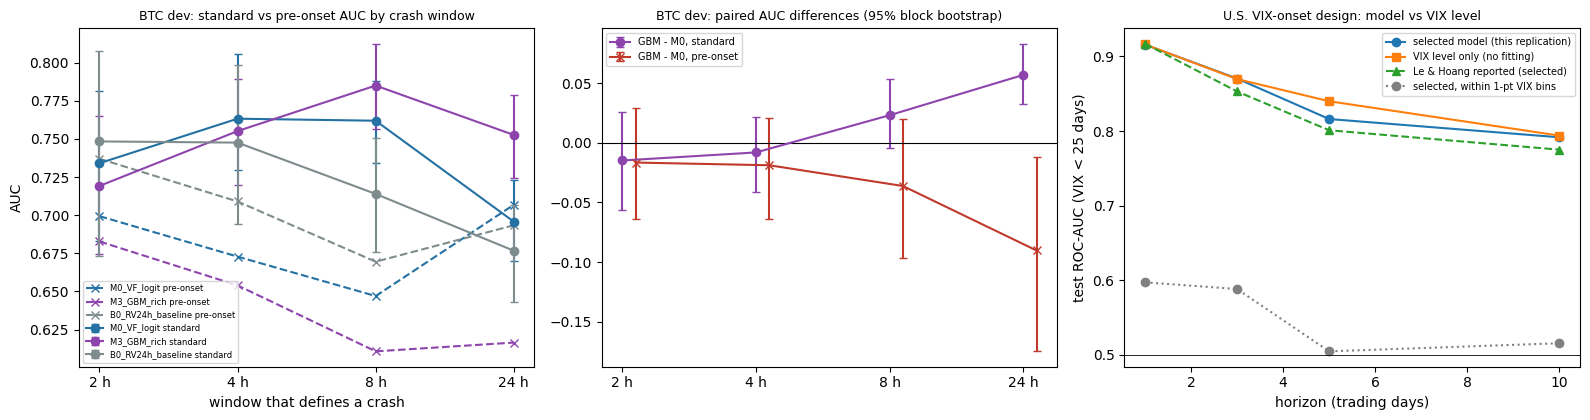

BTC window  2 h | GBM - M0 standard AUC -0.015 [-0.056, +0.026] (not distinguishable) | pre-onset -0.017 [-0.064, +0.029] | pre-onset catches M0 13 vs GBM 8 (M0 only 10, GBM only 5, Holm p 1.0000)
BTC window  4 h | GBM - M0 standard AUC -0.008 [-0.041, +0.021] (not distinguishable) | pre-onset -0.019 [-0.064, +0.021] | pre-onset catches M0 22 vs GBM 7 (M0 only 17, GBM only 2, Holm p 0.0044)
BTC window  8 h | GBM - M0 standard AUC +0.023 [-0.005, +0.053] (not distinguishable) | pre-onset -0.036 [-0.096, +0.020] | pre-onset catches M0 16 vs GBM 4 (M0 only 13, GBM only 1, Holm p 0.0110)
BTC window 24 h | GBM - M0 standard AUC +0.057 [+0.033, +0.083] (A ahead) | pre-onset -0.090 [-0.175, -0.012] | pre-onset catches M0 5 vs GBM 1 (M0 only 4, GBM only 0, Holm p 0.7500)
VIX h= 1 | selected lasso             ROC 0.916 vs VIX level 0.916 (diff -0.000 [-0.002, +0.002]) | within 1-pt VIX bins 0.597 [0.468, 0.712] vs VIX level 0.611 | Le & Hoang selected ROC 0.917 -> pre-specified reading: not sho

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
col = {'M0_VF_logit': '#2471a3', 'M3_GBM_rich': '#8e44ad', 'B0_RV24h_baseline': '#7f8c8d', 'M1_vol_threshold': '#27ae60'}
for sn in ['M0_VF_logit', 'M3_GBM_rich', 'B0_RV24h_baseline']:
    x = SC[SC.score == sn].sort_values('H')
    ax[0].errorbar(np.arange(len(H_LIST)), x.auc_standard, yerr=[x.auc_standard - x.auc_standard_lo, x.auc_standard_hi - x.auc_standard], color=col[sn], marker='o', capsize=3, label=f'{sn} standard')
    ax[0].plot(np.arange(len(H_LIST)), x.auc_pre, color=col[sn], ls='--', marker='x', label=f'{sn} pre-onset')
ax[0].set_xticks(range(len(H_LIST))); ax[0].set_xticklabels([f'{H // 60} h' for H in H_LIST]); ax[0].set_xlabel('window that defines a crash'); ax[0].set_ylabel('AUC')
ax[0].set_title('BTC dev: standard vs pre-onset AUC by crash window', fontsize=9); ax[0].legend(fontsize=6)
x = DIF[(DIF.metric == 'auc_standard') & (DIF.pair == 'M3_GBM_rich - M0_VF_logit')].sort_values('H')
ax[1].errorbar(np.arange(len(H_LIST)), x['diff'], yerr=[x['diff'] - x.lo, x.hi - x['diff']], marker='o', capsize=3, color='#8e44ad', label='GBM - M0, standard')
x = DIF[(DIF.metric == 'auc_pre') & (DIF.pair == 'M3_GBM_rich - M0_VF_logit')].sort_values('H')
ax[1].errorbar(np.arange(len(H_LIST)) + 0.1, x['diff'], yerr=[x['diff'] - x.lo, x.hi - x['diff']], marker='x', capsize=3, color='#c0392b', label='GBM - M0, pre-onset')
ax[1].axhline(0, color='k', lw=0.8); ax[1].set_xticks(range(len(H_LIST))); ax[1].set_xticklabels([f'{H // 60} h' for H in H_LIST])
ax[1].set_title('BTC dev: paired AUC differences (95% block bootstrap)', fontsize=9); ax[1].legend(fontsize=7)
xb = VB.sort_values('h')
ax[2].plot(xb.h, xb.roc_selected, 'o-', label='selected model (this replication)'); ax[2].plot(xb.h, xb.roc_vix_level, 's-', label='VIX level only (no fitting)')
ax[2].plot(xb.h, [LH['selected_roc'][h] for h in xb.h], '^--', label='Le & Hoang reported (selected)')
ax[2].plot(xb.h, xb.within_1pt_selected, 'o:', color='grey', label='selected, within 1-pt VIX bins')
ax[2].axhline(0.5, color='k', lw=0.6); ax[2].set_xlabel('horizon (trading days)'); ax[2].set_ylabel('test ROC-AUC (VIX < 25 days)')
ax[2].set_title('U.S. VIX-onset design: model vs VIX level', fontsize=9); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / '8_ranking_and_vix.png', dpi=140); plt.show()

summary = dict(spec_sha256=SPEC_SHA, status='exploratory, descriptive; BTC development sample only; U.S. VIX re-analysis of a published design; not part of the pre-registration',
               btc_scores_by_window=SC.to_dict('records'), btc_paired_differences=DIF.to_dict('records'), btc_crossover=XO.to_dict('records'),
               btc_paired_events=EP.to_dict('records'), btc_m0_m3_bootstrap=EB.to_dict('records'),
               vix_manifest=[man1, man2], vix_counts=CNT.to_dict('records'), vix_selected=SEL, vix_test_metrics=VM.to_dict('records'),
               vix_bootstrap=VB.to_dict('records'), vix_runup=RU.to_dict('records'), vix_frontier=FR.to_dict('records'))
(OUT / 'RANKING_VIX_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o)))
for H in H_LIST:
    x = DIF[(DIF.H == H) & (DIF.metric == 'auc_standard') & (DIF.pair == 'M3_GBM_rich - M0_VF_logit')].iloc[0]
    y_ = DIF[(DIF.H == H) & (DIF.metric == 'auc_pre') & (DIF.pair == 'M3_GBM_rich - M0_VF_logit')].iloc[0]
    e_ = EP[(EP.H == H) & (EP.endpoint == 'pre') & (EP.pair == 'M0_VF_logit vs M3_GBM_rich')].iloc[0]
    print(f"BTC window {H // 60:2d} h | GBM - M0 standard AUC {x['diff']:+.3f} [{x.lo:+.3f}, {x.hi:+.3f}] ({x.reading}) | pre-onset {y_['diff']:+.3f} [{y_.lo:+.3f}, {y_.hi:+.3f}]"
          f" | pre-onset catches M0 {e_.a_caught} vs GBM {e_.b_caught} (M0 only {e_.a_only}, GBM only {e_.b_only}, Holm p {e_.p_holm:.4f})")
for r in VB.itertuples():
    print(f'VIX h={r.h:2d} | selected {r.selected:17s} ROC {r.roc_selected:.3f} vs VIX level {r.roc_vix_level:.3f} (diff {r.d_roc:+.3f} [{r.d_roc_lo:+.3f}, {r.d_roc_hi:+.3f}]) '
          f'| within 1-pt VIX bins {r.within_1pt_selected:.3f} [{r.within_sel_lo:.3f}, {r.within_sel_hi:.3f}] vs VIX level {r.within_1pt_vix_level:.3f} '
          f'| Le & Hoang selected ROC {LH["selected_roc"][r.h]:.3f} -> pre-specified reading: {r.reading} (post hoc reading: {r.post_hoc_note})')

## Interpretation
- A (Bitcoin): the first block of the last output gives the GBM − M0 standard-AUC difference and its interval for each window. If at 8 and 24 hours the interval lies above 0 while the pre-onset AUC difference is below 0, then "selecting by standard AUC picks the model that is worst at early warning" is a result beyond sampling variation. Comparing π\* with the actual π in `1c_crossover_by_window.csv` shows why. `2a_paired_events_by_window.csv` addresses the same question at the level of alerts and events (Holm-corrected p).
- B (VIX): second block of the last output. When `reading` is "not shown to exceed the VIX level", the current VIX level alone explains the onset score of the model at that h. `3_vix_sample_counts.csv` compares this sample with Table 1 of Le & Hoang (small differences can arise from FRED revisions and missing-data handling). `7_vix_frontier.csv` shows the detection rate of the one-line rule "VIX ≥ c" at the same false-alarm budget next to their Figure 3 values. The π in `6_vix_runup_decomposition.csv` shows how many positive days already in a run-up remain even when I restrict evaluation to VIX < 25 (all three definitions).
- This is not an exact replication of Le & Hoang (integrated variables, XGBoost and preprocessing details differ); it is a reanalysis of what changes when I change the baseline within the same design.